# PBL — Diagnóstico e melhoria de imagens por histogramas

**Disciplina:** Processamento de Imagens  \
**Integrantes:** `Pablo Vinicius`, `Felipe Cruz`  \
**Turma:** CC8NA  \

## Fundamentação teórica (pesquisamos para poder explicar melhor)

Uma imagem em escala de cinza de 8 bits possui intensidades entre 0 (preto) e 255 (branco). O histograma `h(r)` informa quantos pixels têm cada intensidade `r`. Ele não mostra onde os pixels estão, mas revela como os tons estão distribuídos.

- Concentração à esquerda: imagem predominantemente escura.
- Concentração à direita: imagem predominantemente clara.
- Histograma estreito: baixo contraste.
- Dois grupos bem separados: limiarização pode separar fundo e objeto.

As técnicas usadas são transformações de intensidade. **Negativo:** `s = 255 - r`, invertendo a polaridade. **Limiarização:** `s = 255` se `r ≥ T` e `s = 0` caso contrário, gerando uma imagem binária. **Expansão de contraste:** mapeia o intervalo observado `[r_min, r_max]` para `[0, 255]`. **Equalização:** usa a função de distribuição acumulada (CDF) do histograma para redistribuir os níveis. **Gamma:** `s = 255 (r/255)^γ`; para `γ < 1`, tons escuros são ampliados.

Em todos os casos, o diagnóstico deve ser conferido visualmente **e** pelo histograma. A transformação melhora um aspecto específico; ela não cria informação inexistente e pode introduzir efeitos indesejados, como amplificação de ruído ou perda de tons.

In [ ]:
import numpy as np
import cv2
import matplotlib.pyplot as plt

PASTA_IMAGENS = 'imagens'

caminhos = {
    1: 'imagem_01.png',
    2: 'imagem_02.png',
    3: 'imagem_03.png',
    4: 'imagem_04.png',
    5: 'imagem_05.png',
}

imagens = {}
for numero, caminho in caminhos.items():
    img = cv2.imread(caminho, cv2.IMREAD_GRAYSCALE)
    if img is None:
        raise FileNotFoundError(f'Não foi possível abrir: {caminho}')
    imagens[numero] = img

print('Cinco imagens carregadas em escala de cinza.')

Cinco imagens carregadas em escala de cinza.


In [ ]:
def calclist(img):
    bars = np.zeros(shape=256, dtype=np.int64)

    for pixel in img.ravel():
        bars[pixel] += 1

    return bars


def plotar_histograma(ax, img, titulo):
    hist = calclist(img)
    ax.set_title(titulo, fontsize=11, fontweight='bold')
    ax.set_xlabel('Intensidade (0 a 255)')
    ax.set_ylabel('Quantidade de pixels')
    ax.bar(range(256), hist, color='purple', width=0.8, edgecolor='none')
    ax.set_xlim([0, 255])
    ax.grid(axis='y', alpha=0.25)
    return hist


def mostrar_comparacao(original, resultado, titulo_original, titulo_resultado):
    # O arranjo 2x2 reúne imagens e seus histogramas antes/depois.
    fig, ax = plt.subplots(2, 2, figsize=(15, 10))
    ax[0, 0].imshow(original, cmap='gray', vmin=0, vmax=255)
    ax[0, 0].set_title(titulo_original, fontweight='bold')
    ax[0, 0].axis('off')

    ax[0, 1].imshow(resultado, cmap='gray', vmin=0, vmax=255)
    ax[0, 1].set_title(titulo_resultado, fontweight='bold')
    ax[0, 1].axis('off')

    plotar_histograma(ax[1, 0], original, 'Histograma original')
    plotar_histograma(ax[1, 1], resultado, 'Histograma final')
    plt.tight_layout()
    plt.show()


def resumo_numerico(img):
    # Estatísticas simples que ajudam a sustentar o diagnóstico.
    print(f'mínimo = {img.min()} | máximo = {img.max()} | média = {img.mean():.2f} | desvio padrão = {img.std():.2f}')

# Funções de correção de imagem


In [ ]:
# Limiarização

def limiarizar(img: np.ndarray, limiar: int) -> np.ndarray:
  img_limiarizada = np.where(img >= limiar, 255, 0).astype(np.uint8)
  return img_limiarizada



# Correção Gamma

def correcao_gama(img: np.ndarray, nivel_gamma: np.float32) -> np.ndarray:
  normalizada = img.astype(np.float32) / 255.0 # normaliza entre 0 e 1
  img_gamma = 255.0 * (normalizada ** nivel_gamma) # aplica o nível de gamma em potencia
  img_gamma = np.clip(img_gamma, 0, 255).astype(np.uint8) # volta para 0 a 255
  return img_gamma



# Negativo digital

def negativo(img):
    imgNegativo = (255 - img).astype(np.uint8)

    return imgNegativo



# Equalização

def equalizar_manual(img):
    hist = calclist(img)
    cdf = np.cumsum(hist)

    # Primeiro valor não nulo da CDF: evita mapear níveis ausentes de forma indevida.
    cdf_min = cdf[cdf > 0][0]
    total = img.size

    # LUT explícita: cada índice r recebe a intensidade transformada s.
    lut = (cdf - cdf_min) * 255.0 / (total - cdf_min)
    lut = np.clip(np.round(lut), 0, 255).astype(np.uint8)
    return lut[img]



# Expansão

def expandir_contraste(img):
    r_min = int(img.min())
    r_max = int(img.max())

    if r_max == r_min:
        return img.copy()

    # Cálculo em float evita truncamento durante a transformação linear.
    expandida = (img.astype(np.float32) - r_min) * 255.0 / (r_max - r_min)
    return np.clip(expandida, 0, 255).astype(np.uint8)

# Caso 1 — Limiarização

**Diagnóstico:** O fundo escuro e os grãos claros formam dois grupos de intensidades. No histograma, observamos uma concentração nos tons baixos (fundo) e outra nos tons altos (grãos), com uma região menos povoada entre elas. Por isso, acreditamos que a limiarização seria melhor para separar mais evidentemente os grãos do fundo.

mínimo = 0 | máximo = 220 | média = 56.55 | desvio padrão = 51.19


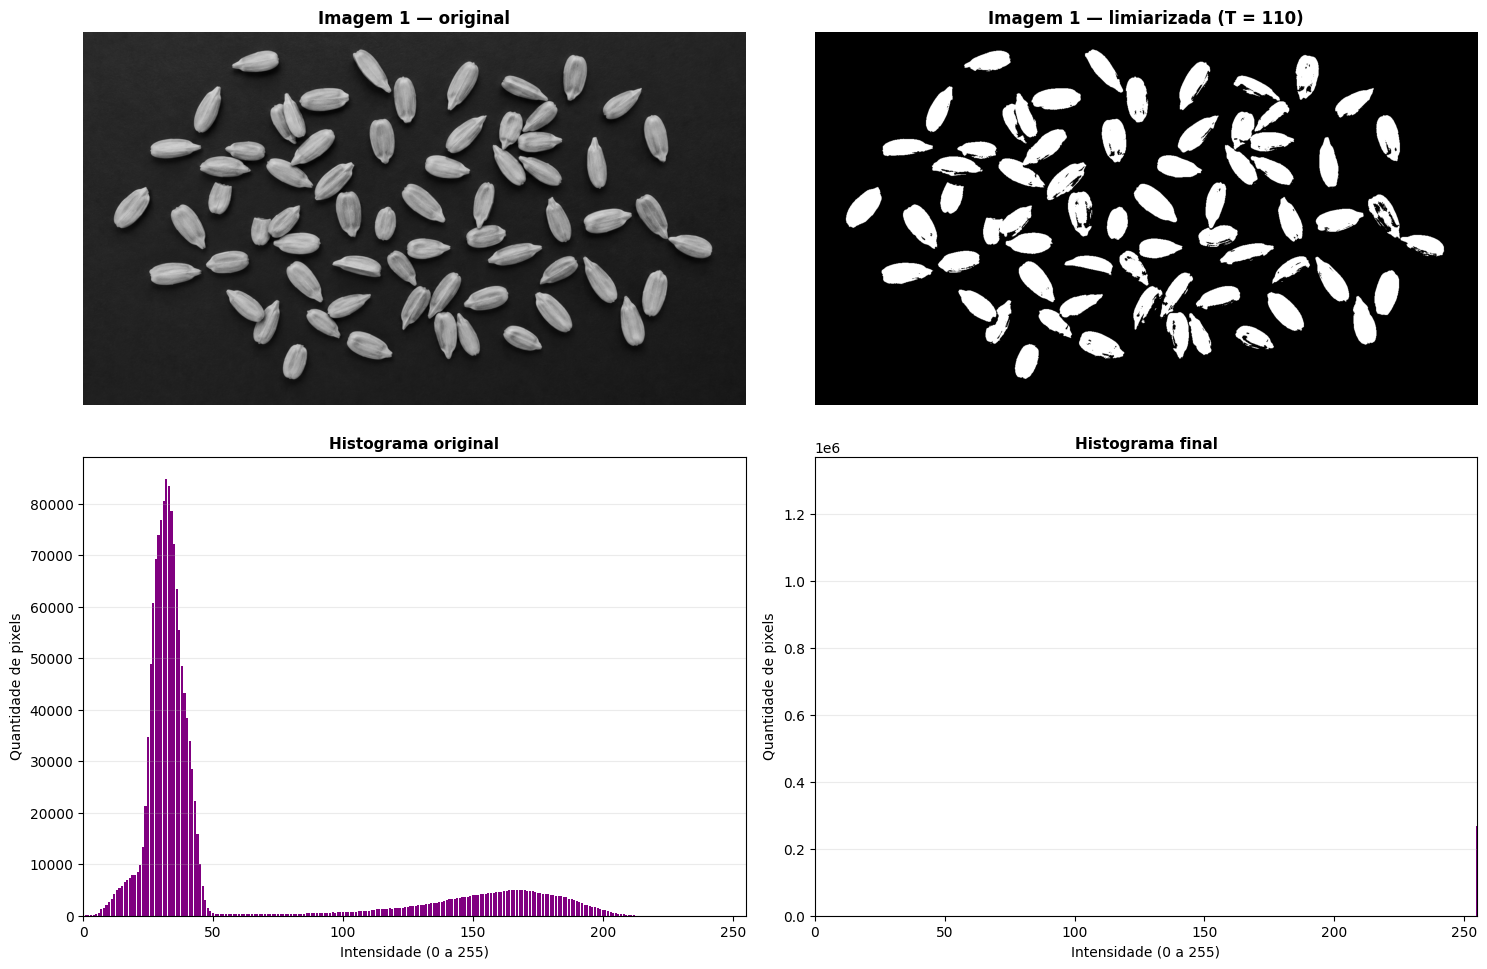

In [ ]:
limiarizada1 = limiarizar(img=imagens[1], limiar=125)

resumo_numerico(imagens[1])
mostrar_comparacao(imagens[1], limiarizada1, 'Imagem 1 — original', f'Imagem 1 — limiarizada (T = {T})')

**Justificativa.** A limiarização converte a diferença de intensidade entre fundo e grãos em uma separação direta entre preto e branco. O histograma final concentra-se apenas em 0 e 255, o que confirma a binarização. Ela é adequada como etapa de preparação para contagem ou medição dos grãos, mas elimina as texturas internas.

# Caso 2 — Correção Gamma

**Diagnóstico.** A cena está subexposta: grande parte dos pixels aparece nos níveis baixos e muitos detalhes ficam ocultos nas sombras. Um simples deslocamento de brilho poderia saturar os poucos tons claros; gamma menor que 1 amplia principalmente os níveis escuros.

**Técnica e parâmetro.** Usamos `γ = 0.30`. Como `γ < 1`, a curva se eleva nos tons baixos. O valor pode ser ajustado: diminuir gamma clareia mais a cena; aproximá-lo de 1 reduz o efeito.

mínimo = 0 | máximo = 243 | média = 11.69 | desvio padrão = 12.08


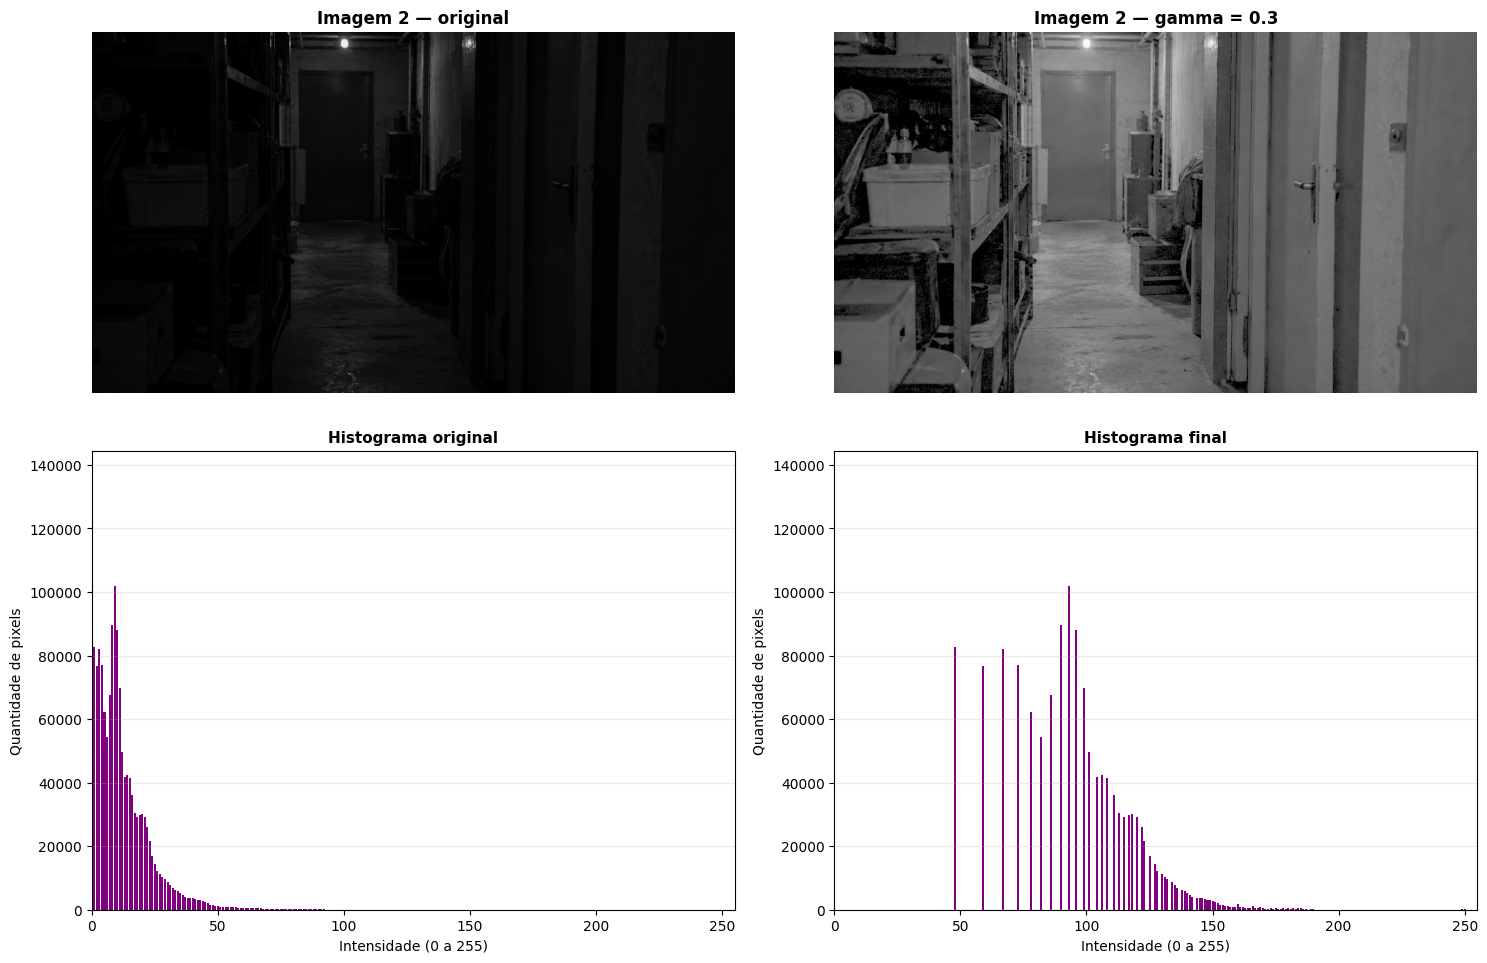

In [ ]:
gamma2 = correcao_gama(img=imagens[2], nivel_gamma=0.30)

resumo_numerico(imagens[2])
mostrar_comparacao(imagens[2], gamma2, 'Imagem 2 — original', f'Imagem 2 — gamma = {0.30}')

**Justificativa.** A correção gamma desloca a massa do histograma para intensidades maiores sem mudar a ordem dos pixels. Assim, superfícies e objetos antes quase pretos tornam-se visíveis. O ganho visual deve ser equilibrado: um gamma muito pequeno também torna ruído e áreas sem importância mais aparentes.

# Caso 3 — Negativo digital

**Diagnóstico.** A imagem de inspeção tem objetos claros sobre um fundo escuro e muitos detalhes internos em tons médios. A polaridade pode dificultar a leitura para a finalidade de análise. Neste caso, o negativo é usado para testar a polaridade oposta, preservando toda a informação tonal.

**Técnica e parâmetro.** Não há parâmetro: para cada pixel `r`, usar `s = 255 − r`. É uma transformação reversível; aplicar o negativo duas vezes recupera a imagem original.

mínimo = 4 | máximo = 230 | média = 48.26 | desvio padrão = 44.13


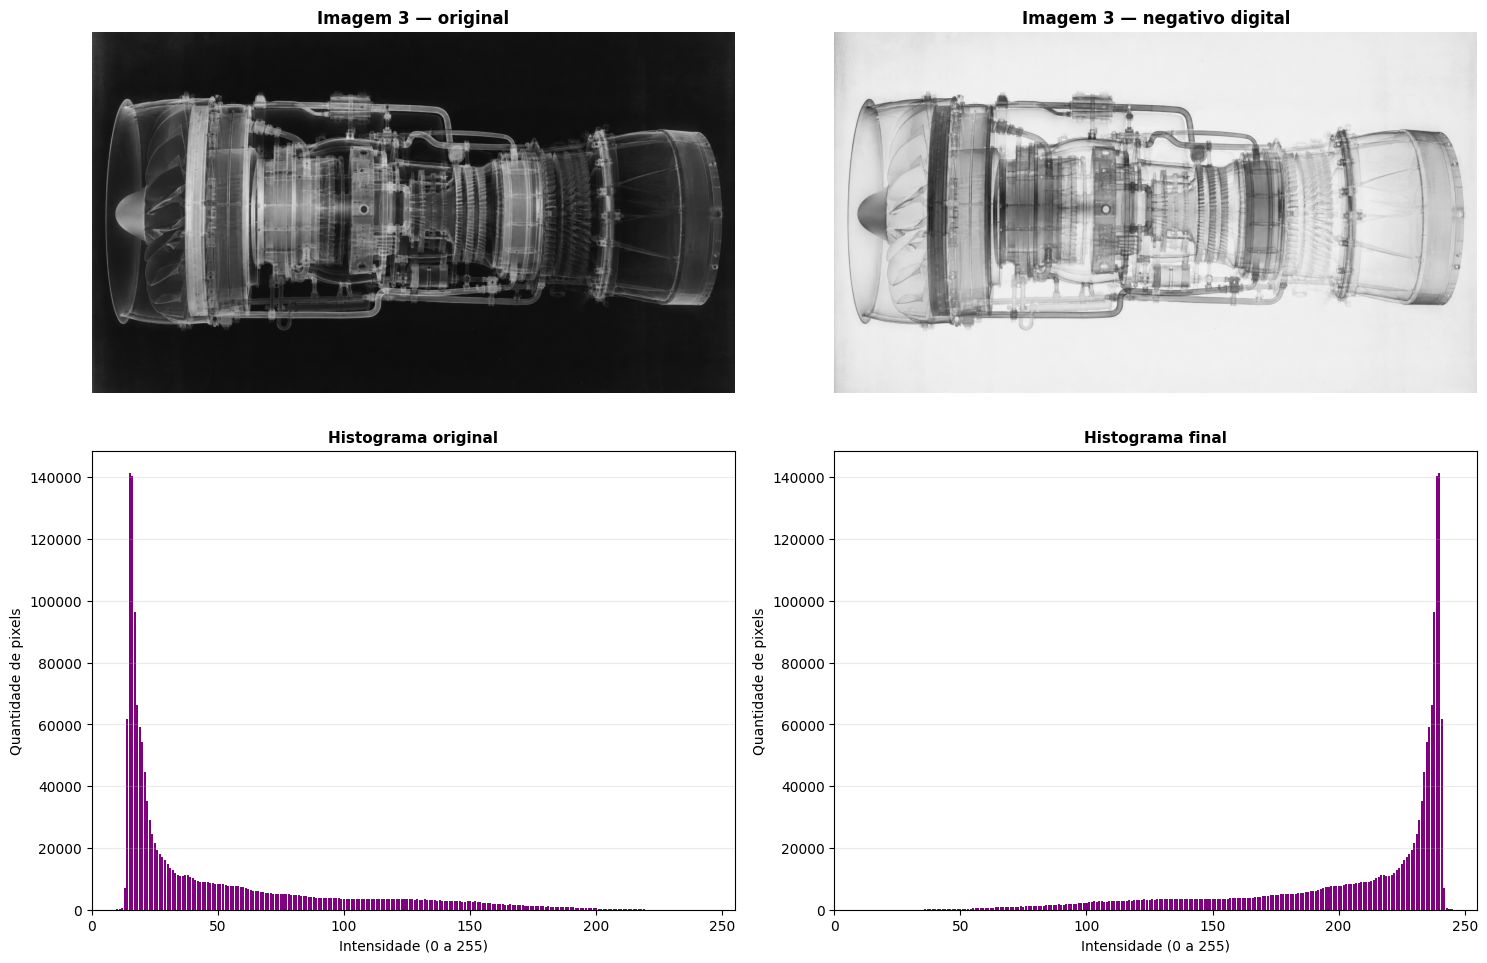

In [ ]:
img3 = imagens[3]
negativo3 = negativo(img3)

resumo_numerico(img3)
mostrar_comparacao(img3, negativo3, 'Imagem 3 — original', 'Imagem 3 — negativo digital')

**Justificativa.** O negativo espelha o histograma: cada nível `r` é enviado para `255 − r`. Ele não aumenta o contraste, mas oferece uma apresentação alternativa dos detalhes da peça e pode favorecer a inspeção visual dependendo do monitor e do observador. A decisão final deve comparar qual polaridade permite distinguir melhor as estruturas.

# Caso 4 — Equalização de histograma

**Diagnóstico.** A imagem tem aparência acinzentada e pouco contraste local por causa da névoa/iluminação uniforme. Seus tons ocupam uma faixa intermediária relativamente concentrada; os contornos de prédios, árvores e carros ficam pouco separados do fundo.

**Técnica e parâmetro.** Aplicar equalização global. A tabela de mapeamento é calculada da CDF do histograma manual, sem `cv2.equalizeHist`. Não há parâmetro de ajuste, mas é importante observar se a equalização deixa a textura ou o ruído excessivos.

mínimo = 56 | máximo = 217 | média = 98.40 | desvio padrão = 21.98


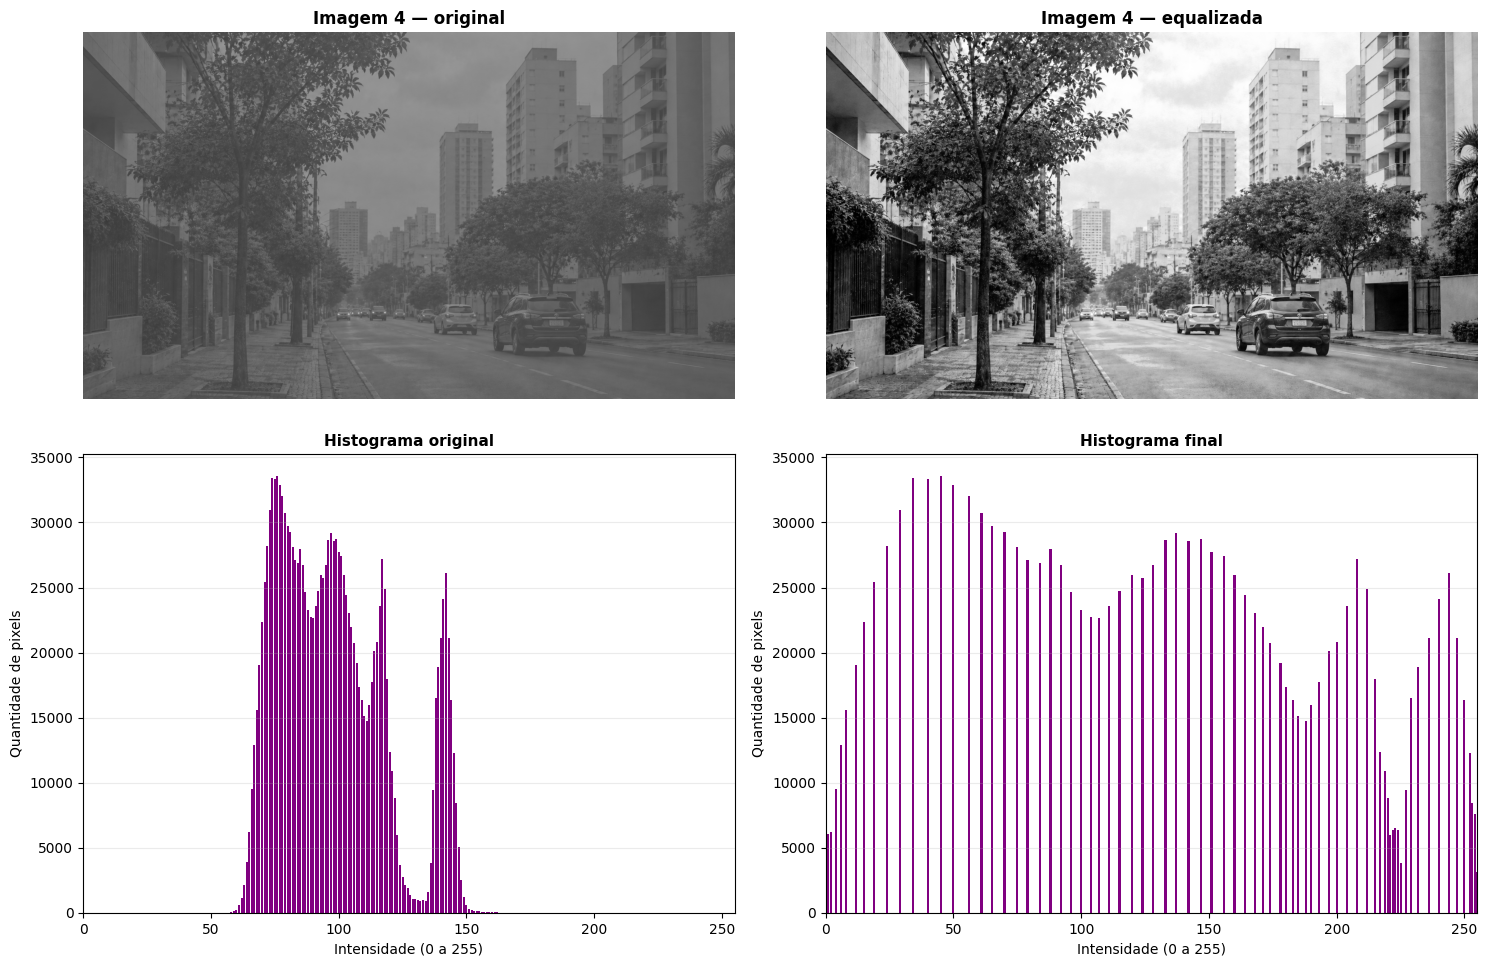

In [ ]:
img4 = imagens[4]
equalizada4 = equalizar_manual(img4)

resumo_numerico(img4)
mostrar_comparacao(img4, equalizada4, 'Imagem 4 — original', 'Imagem 4 — equalizada')

**Justificativa.** A equalização espalha os níveis mais frequentes ao longo de uma faixa maior de intensidades. Isso aumenta a separação entre regiões da cena e destaca contornos de objetos urbanos. O histograma final tende a ficar mais distribuído, mas não necessariamente perfeitamente plano, pois a imagem tem níveis discretos e a transformação usa arredondamento.

# Caso 5 — Expansão de contraste

**Diagnóstico.** A peça e o fundo usam uma faixa muito estreita de cinza, produzindo aparência lavada. Diferentemente da imagem 4, o problema principal é a faixa dinâmica reduzida, não a necessidade de redistribuir cada frequência.

**Técnica e parâmetro.** Usar expansão linear de `[r_min, r_max]` para `[0, 255]`. Os limites são extraídos da própria imagem. Nesta imagem, verificar o resultado é essencial porque um único pixel extremo poderia ampliar ruído; se isso ocorrer, uma versão futura pode usar limites percentuais, também calculados manualmente.

mínimo = 75 | máximo = 140 | média = 102.97 | desvio padrão = 10.15


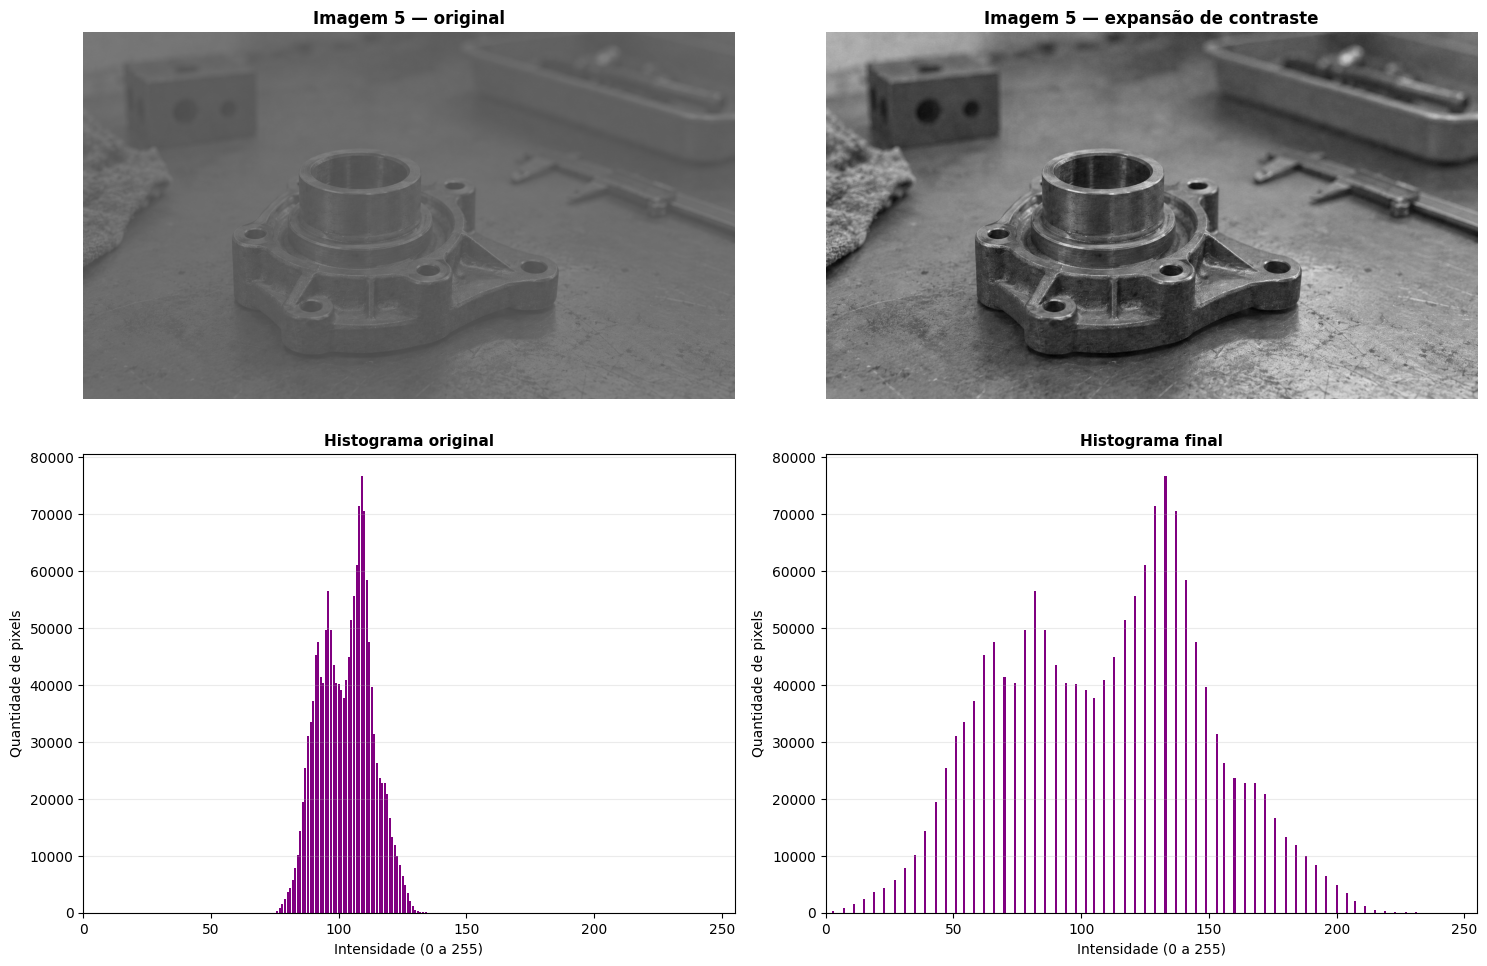

In [ ]:
img5 = imagens[5]
expandida5 = expandir_contraste(img5)

resumo_numerico(img5)
mostrar_comparacao(img5, expandida5, 'Imagem 5 — original', 'Imagem 5 — expansão de contraste')

**Justificativa.** A expansão aumenta proporcionalmente as diferenças já existentes entre os tons da peça, do fundo e das sombras. Por isso, as bordas e a geometria ficam mais evidentes. O histograma final ocupa uma faixa mais ampla, preservando a ordem relativa das intensidades, ao contrário da equalização, que muda essa distribuição de forma não linear.

# Equalização -> Quantização — Imagem 5

Por fim, decidimos que a equalização seria uma boa alternativa para a imagem 5 também.

mínimo = 75 | máximo = 140 | média = 102.97 | desvio padrão = 10.15


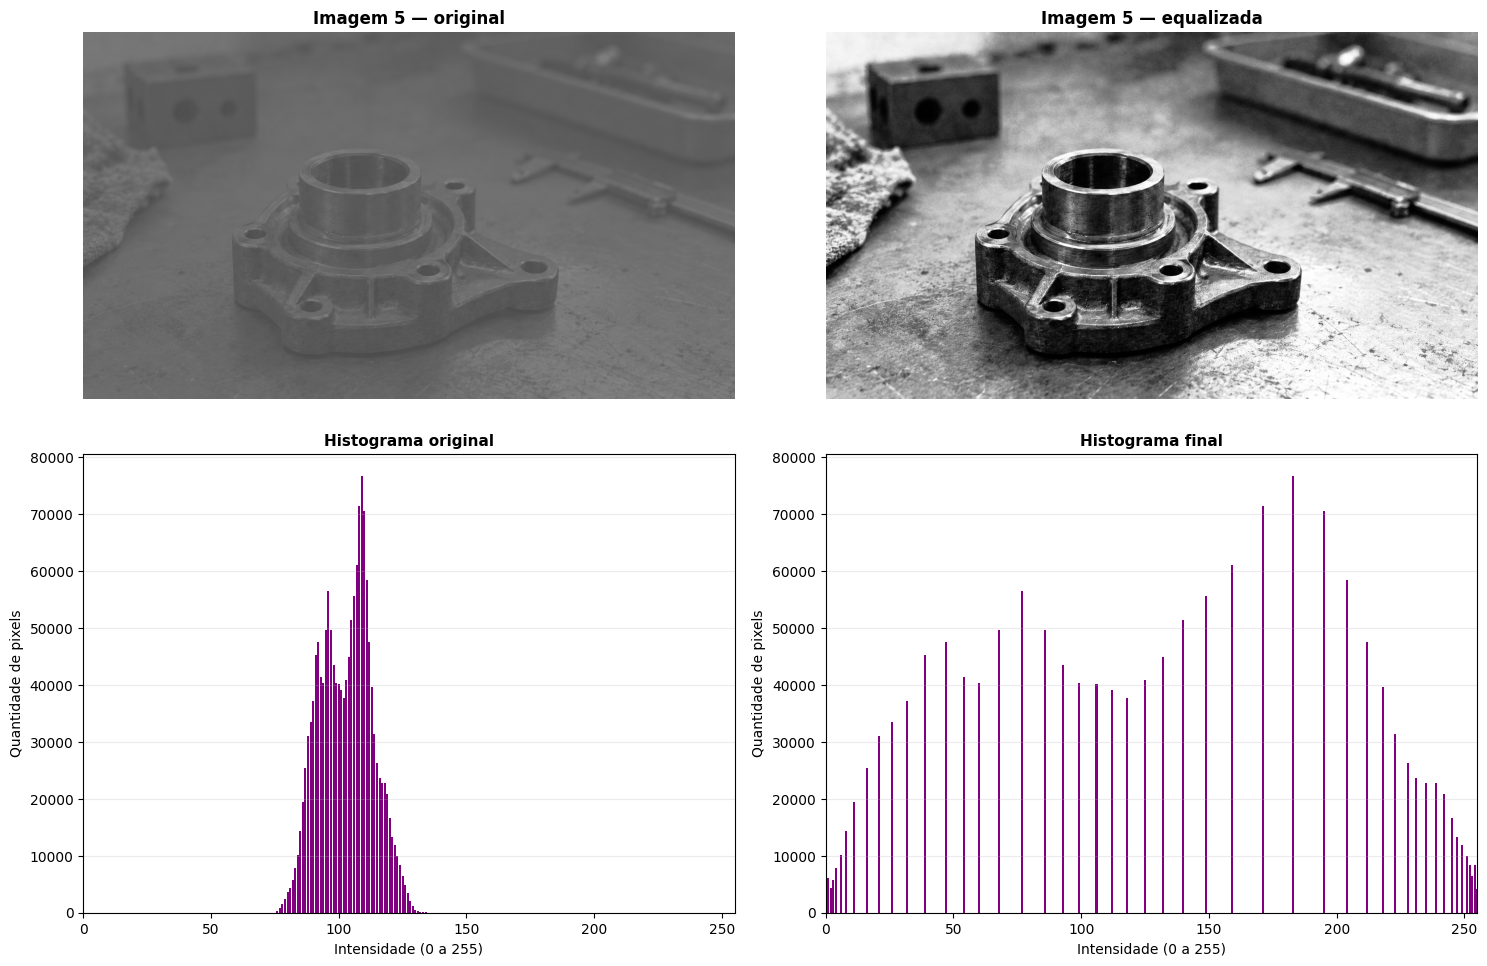

In [ ]:
img5 = imagens[5]
equalizada5 = equalizar_manual(img5)

resumo_numerico(img5)
mostrar_comparacao(img5, equalizada5, 'Imagem 5 — original', 'Imagem 5 — equalizada')

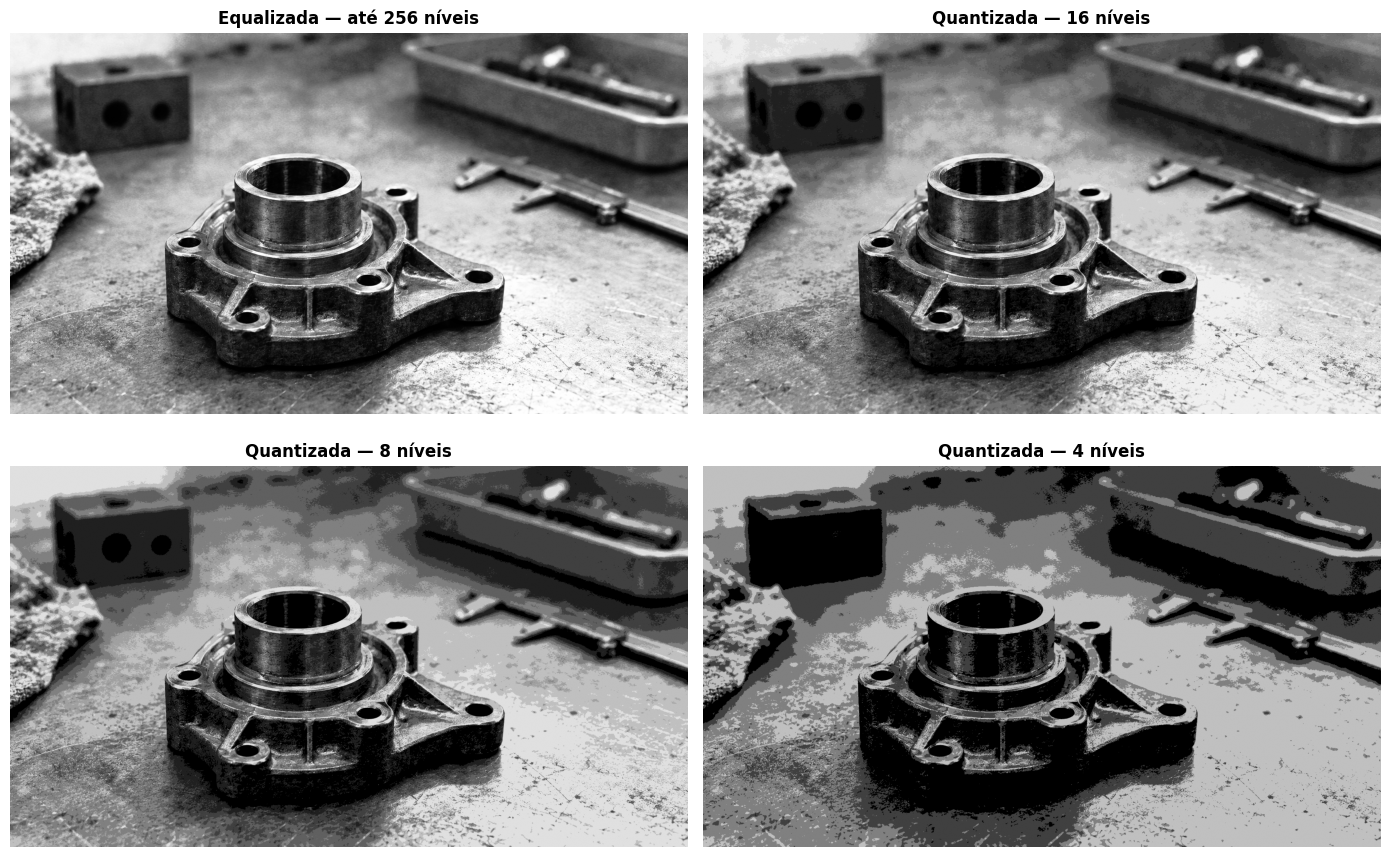

In [ ]:
def quantizar(img, niveis):
    if niveis not in (4, 8, 16):
        raise ValueError('Use 4, 8 ou 16 níveis neste experimento.')

    delta = 256 // niveis
    # Divide em intervalos e usa o nível representativo do início de cada intervalo.
    quantizada = (img.astype(np.uint16) // delta) * delta
    return np.clip(quantizada, 0, 255).astype(np.uint8)


q16 = quantizar(equalizada5, 16)
q8 = quantizar(equalizada5, 8)
q4 = quantizar(equalizada5, 4)

fig, ax = plt.subplots(2, 2, figsize=(14, 9))
itens = [(equalizada5, 'Equalizada — até 256 níveis'), (q16, 'Quantizada — 16 níveis'),
         (q8, 'Quantizada — 8 níveis'), (q4, 'Quantizada — 4 níveis')]

for eixo, (imagem, titulo) in zip(ax.ravel(), itens):
    eixo.imshow(imagem, cmap='gray', vmin=0, vmax=255)
    eixo.set_title(titulo, fontweight='bold')
    eixo.axis('off')

plt.tight_layout()
plt.show()

**Comentário sobre a quantização.** Em 16 níveis, a estrutura principal ainda deve parecer próxima da original, embora transições suaves já possam perder continuidade. Em 8 níveis, as mudanças tonais ficam mais abruptas. Em 4 níveis, a perda tende a ser a mais perceptível: sombras, relevo e gradientes são representados por poucos patamares, produzindo faixas visíveis.

## Conclusão

A escolha da técnica foi baseada no formato predominante do histograma e na finalidade visual de cada imagem: separação de objeto e fundo (limiarização), recuperação de sombras (gamma), troca de polaridade (negativo), distribuição comprimida em tons médios (equalização) e faixa dinâmica estreita (expansão). Os parâmetros propostos são pontos de partida: a comparação em 2x2 permite justificar visualmente qualquer ajuste feito pela equipe.